<a href="https://colab.research.google.com/github/lilianeuwase2/math_forML-Formative3/blob/main/gradient_descent.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Imports of libraries to be used

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.differentiate import derivative
from matplotlib.ticker import MaxNLocator

data given with their values

In [2]:
x=np.array([[1.0,3.0],
            [4.0,10.0]])
y=np.array([5.0,6.0])
m=np.array([-1.0,2.0])
b=np.array([1.0,1.0])
alpha=0.01
n_steps=3

m_start, b_start = m.copy(), b.copy()

the forward function for yhat=mx+b

In [3]:
def forward(x,m,b):
    return x @ m + b

print("Error with the starting m and b:", forward(x,m,b))

Error with the starting m and b: [ 6. 17.]


the error calculation and function

In [4]:
def get_error(x,y,m,b):
    return forward(x,m,b) - y

print("Error with the starting m and b:", get_error(x,y,m,b))

Error with the starting m and b: [ 1. 11.]


In [5]:
def get_cost(x,y,m,b):
    error = get_error(x,y,m,b)
    return np.mean(error ** 2)

the partial derivative function that shows how a function changes when one value is changed while others stay fixed

In [6]:
def partial_derivative(f,point,i):
    def f_of_t(t):
        results=[]
        for t_value in np.ravel(t):
            trial = point.copy()
            trial[i] = t_value
            results.append(f(trial))
        return np.array(results).reshape(np.shape(t))
    return derivative(f_of_t, point[i]).df

the gradient where its the derivative of the cost with respect to m and b values

In [7]:
def gradient(x,y,m,b):
    point=np.concatenate([m,b]).astype(float)
    cost = lambda p: get_cost(x,y,p[:2],p[2:])
    slopes = [partial_derivative(cost,point,i) for i in range(4)]
    d_m = np.array(slopes[:2])
    d_b = np.array(slopes[2:])
    return d_m, d_b

d_m, d_b = gradient(x,y,m,b)
print("d cost / d m from SciPy:", d_m)
print("d cost / d b from SciPy:", d_b)

d cost / d m from SciPy: [ 45. 113.]
d cost / d b from SciPy: [ 1. 11.]


the update we move m and b against the gradient

In [8]:
def update(x, y):
    global m, b
    d_m, d_b = gradient(x, y, m, b)
    m = m - alpha * d_m
    b = b - alpha * d_b

the loop of updating each value after an iteration

In [9]:
m, b = m_start.copy(), b_start.copy()

m_history = [m.copy()]
b_history = [b.copy()]
cost_history = [get_cost(x, y, m, b)]
print(f"Start     error = {get_error(x, y, m, b)}   cost = {cost_history[0]:.4f}")

for i in range(n_steps):
    update(x, y)

    m_history.append(m.copy())
    b_history.append(b.copy())
    cost_history.append(get_cost(x, y, m, b))

    if n_steps <= 10 or (i + 1) % 10 == 0:
        print(f"Update {i+1}  m = {np.round(m, 4)}   b = {np.round(b, 4)}")
        print(f"          error = {np.round(get_error(x, y, m, b), 4)}   cost = {cost_history[-1]:.4f}")

Start     error = [ 1. 11.]   cost = 61.0000
Update 1  m = [-1.45  0.87]   b = [0.99 0.89]
          error = [-2.85 -2.21]   cost = 6.5033
Update 2  m = [-1.3331  1.1765]   b = [1.0185 0.9121]
          error = [-1.7851  1.3447]   cost = 2.4974
Update 3  m = [-1.369   1.0956]   b = [1.0364 0.8987]
          error = [-2.0459  0.3783]   cost = 2.1645


In [10]:
print("Final m:", m)
print("Final b:", b)
print("Final predictions:", forward(x, m, b))
print("Targets y:        ", y)
print("Final error:", get_error(x, y, m, b))
print("Final cost (MSE):", get_cost(x, y, m, b))

Final m: [-1.369037  1.095583]
Final b: [1.036351 0.898653]
Final predictions: [2.954063 6.378335]
Targets y:         [5. 6.]
Final error: [-2.045937  0.378335]
Final cost (MSE): 2.1644977900970015


plot 1: how m and b change over the iterations

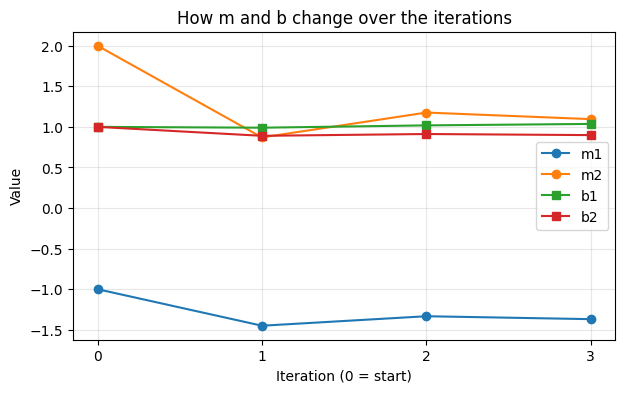

In [11]:
iterations = np.arange(len(cost_history))
m_history = np.array(m_history)
b_history = np.array(b_history)

plt.figure(figsize=(7, 4))
plt.plot(iterations, m_history[:, 0], marker="o", label="m1")
plt.plot(iterations, m_history[:, 1], marker="o", label="m2")
plt.plot(iterations, b_history[:, 0], marker="s", label="b1")
plt.plot(iterations, b_history[:, 1], marker="s", label="b2")
plt.title("How m and b change over the iterations")
plt.xlabel("Iteration (0 = start)")
plt.ylabel("Value")
plt.gca().xaxis.set_major_locator(MaxNLocator(integer=True))
plt.legend()
plt.grid(alpha=0.3)
plt.show()

plot 2: how the error changes over the iterations

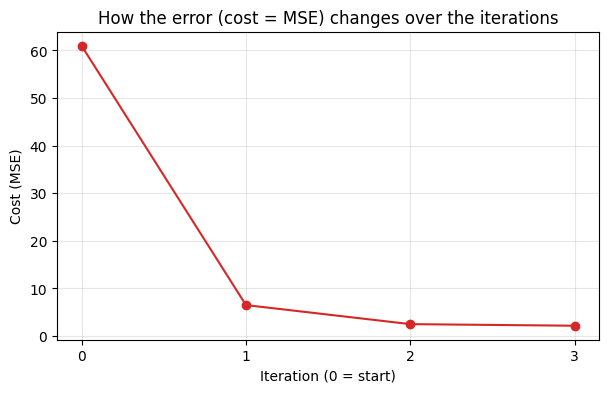

In [12]:
plt.figure(figsize=(7, 4))
plt.plot(iterations, cost_history, marker="o", color="tab:red")
plt.title("How the error (cost = MSE) changes over the iterations")
plt.xlabel("Iteration (0 = start)")
plt.ylabel("Cost (MSE)")
plt.gca().xaxis.set_major_locator(MaxNLocator(integer=True))
plt.grid(alpha=0.3)
plt.show()